# Aberration Simulation

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch03/ch03-04.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.colors as colors

## Initialize variables

In [5]:
# --- 1. Configuration & Parameters ---
# Grid Resolution
N = 256          # Resolution for the aperture
PAD_FACTOR = 4   # Padding for FFT (higher = smoother PSF)

# Aberration Coefficients (Spherical Only)
tilt = 0.0
focus = 0.0
ast = 0.0
coma = 0.0
sph = 5.0        # Non-zero Spherical Aberration
offaxis = 0.0    # Position h

# --- 2. Coordinate System ---
# Create a meshgrid from -1 to 1
lin = np.linspace(-1, 1, N)
X, Y = np.meshgrid(lin, lin)

# Convert to Polar Coordinates
Rho = np.sqrt(X**2 + Y**2)
Theta = np.arctan2(Y, X)

# Mask for the Unit Circle (Aperture)
# We use NaN for plotting transparency, 0 for FFT calculation
mask = Rho <= 1.0

## Aberration function

In [6]:
# --- 3. Calculate Wavefront Aberration (W) ---
# Formula: W = T*h^3*r*cos(t) + F*h^2*r^2 + A*h^2*r^2*cos^2(t) + C*h*r^3*cos(t) + S*r^4
# Since h (offaxis) is 0, only Spherical (S*r^4) matters here.
W = np.zeros_like(Rho)

# Calculate terms
# (Included full logic for completeness, even though most are 0)
h = offaxis
W += tilt * (h**3) * Rho * np.cos(Theta)           # Distortion
W += focus * (h**2) * (Rho**2)                     # Field Curvature
W += ast * (h**2) * (Rho**2) * (np.cos(Theta)**2)  # Astigmatism
W += coma * h * (Rho**3) * np.cos(Theta)           # Coma
W += sph * (Rho**4)                                # Spherical

# Apply mask (Set values outside aperture to NaN for plotting)
W_plot = W.copy()
W_plot[~mask] = np.nan

# --- 4. Calculate PSF (via FFT) ---
# 1. Create Complex Pupil Function: A * e^(i * 2*pi * W)
Pupil = np.zeros_like(W, dtype=complex)
Pupil[mask] = np.exp(1j * 2 * np.pi * W[mask])

# 2. Perform FFT
# We pad the array to increase resolution in the frequency domain (smooth PSF)
fft_size = N * PAD_FACTOR
psf_complex = np.fft.fftshift(np.fft.fft2(Pupil, s=(fft_size, fft_size)))
psf_intensity = np.abs(psf_complex)**2

# 3. Log Scale for Visualization
# We normalize and log-scale to make faint Airy rings visible
psf_intensity /= np.max(psf_intensity)
psf_log = np.log10(psf_intensity + 1e-5) # Add small epsilon to avoid log(0)

## Static Plot

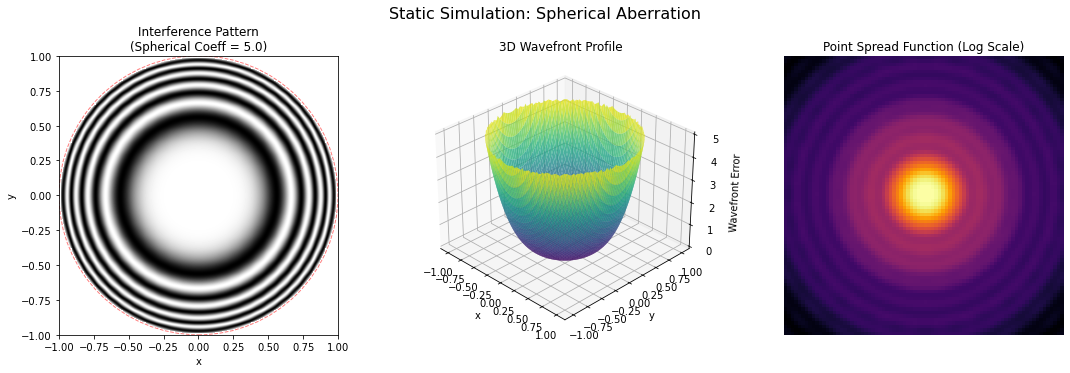

In [7]:
# --- 5. Plotting ---
fig = plt.figure(figsize=(18, 5.5))
plt.subplots_adjust(wspace=0.3)

# Subplot 1: Wavefront Phase (Interference Pattern)
ax1 = fig.add_subplot(1, 3, 1)
# Calculate cos(2*pi*W) for interference fringes
interference = np.cos(2 * np.pi * W_plot)
im1 = ax1.imshow(interference, extent=[-1, 1, -1, 1], cmap='gray', origin='lower')
ax1.set_title(f"Interference Pattern\n(Spherical Coeff = {sph})")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
# Draw unit circle
circle = plt.Circle((0, 0), 1, color='red', fill=False, linestyle='--', alpha=0.5)
ax1.add_patch(circle)

# Subplot 2: 3D Wavefront Profile
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
# Downsample for wireframe performance (stride)
stride = 4
wire = ax2.plot_surface(X, Y, W_plot, rstride=stride, cstride=stride, 
                        cmap='viridis', edgecolor='none', alpha=0.8)
ax2.set_title("3D Wavefront Profile")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("Wavefront Error")
ax2.set_zlim(0, sph) # Adjust limit based on coefficient
ax2.view_init(elev=30, azim=-45) # "Square" perspective

# Subplot 3: Point Spread Function (PSF)
ax3 = fig.add_subplot(1, 3, 3)
# Zoom into the center of the FFT result
center = fft_size // 2
zoom_radius = 40  # Adjust this to zoom in/out of the PSF center
psf_zoom = psf_log[center-zoom_radius:center+zoom_radius, 
                   center-zoom_radius:center+zoom_radius]

im3 = ax3.imshow(psf_zoom, cmap='inferno', origin='lower')
ax3.set_title("Point Spread Function (Log Scale)")
ax3.axis('off') # Hide axis ticks for the PSF

plt.suptitle("Static Simulation: Spherical Aberration", fontsize=16)
plt.savefig('spherical_aberration.png', dpi=150)
plt.show()

## Make interactive with `matplotlib` and `ipywidgets`

In [ ]:
%matplotlib widget
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D # Explicit import for safety

# --- 1. Optimization Constants ---
# High res for 2D (Interference/PSF)
N_2D = 128
# Low res for 3D (Critical for speed)
N_3D = 32       
FFT_PAD = 2

# --- 2. Pre-allocate Grids ---
# 2D Grid
lin_2d = np.linspace(-1, 1, N_2D)
X2, Y2 = np.meshgrid(lin_2d, lin_2d)
R2 = np.sqrt(X2**2 + Y2**2)
T2 = np.arctan2(Y2, X2)
MASK2 = R2 <= 1.0

# 3D Grid
lin_3d = np.linspace(-1, 1, N_3D)
X3, Y3 = np.meshgrid(lin_3d, lin_3d)
R3 = np.sqrt(X3**2 + Y3**2)
T3 = np.arctan2(Y3, X3)
MASK3 = R3 <= 1.0
X3_plot = X3.copy()
Y3_plot = Y3.copy()
X3_plot[~MASK3] = np.nan
Y3_plot[~MASK3] = np.nan

# --- 3. Physics ---
def calculate_W(rho, theta, params):
    h = params['offaxis']
    # W = T*h^3*r*cos(t) + F*h^2*r^2 + A*h^2*r^2*cos^2(t) + C*h*r^3*cos(t) + S*r^4
    return (params['tilt']  * h**3 * rho * np.cos(theta) +
            params['focus'] * h**2 * rho**2 +
            params['ast']   * h**2 * rho**2 * np.cos(theta)**2 +
            params['coma']  * h    * rho**3 * np.cos(theta) +
            params['sph']   * rho**4)

# --- 4. Setup Output Container ---
# This is the most robust way to display widgets in VS Code
plot_output = widgets.Output()

# Global references for plot objects
im_int = None
im_psf = None
surf = None
ax_3d = None
fig = None

with plot_output:
    # Create figure INSIDE the output context
    plt.close('all') # Cleanup old figures
    fig = plt.figure(figsize=(9, 4))
    fig.canvas.header_visible = False
    fig.canvas.footer_visible = False

    # Layout
    gs = fig.add_gridspec(1, 3)
    ax_int = fig.add_subplot(gs[0, 0])
    ax_3d  = fig.add_subplot(gs[0, 1], projection='3d')
    ax_psf = fig.add_subplot(gs[0, 2])

    # 1. Interference Init
    im_int = ax_int.imshow(np.zeros((N_2D, N_2D)), extent=[-1,1,-1,1], cmap='gray', origin='lower', vmin=-1, vmax=1)
    ax_int.set_title("Interference")
    ax_int.axis('off')

    # 2. 3D Init
    surf = ax_3d.plot_surface(X3_plot, Y3_plot, np.zeros_like(R3), cmap='viridis')
    ax_3d.set_title("Wavefront")
    ax_3d.set_zlim(-1, 1)
    ax_3d.axis('off')

    # 3. PSF Init
    im_psf = ax_psf.imshow(np.zeros((N_2D, N_2D)), cmap='inferno', origin='lower')
    ax_psf.set_title("PSF (Log)")
    ax_psf.axis('off')
    
    plt.tight_layout()
    plt.show() # Required inside Output widget

# --- 5. Update Logic ---
def update_view(change=None):
    global surf
    
    # 1. Params
    params = {
        'tilt': s_tilt.value, 'focus': s_focus.value, 
        'ast': s_ast.value,   'coma': s_coma.value, 
        'sph': s_sph.value,   'offaxis': s_offaxis.value
    }
    
    # 2. Update 2D (Fast)
    W2 = calculate_W(R2, T2, params)
    
    # Interference
    interf = np.cos(2 * np.pi * W2)
    interf[~MASK2] = 0
    im_int.set_data(interf)
    
    # PSF (FFT)
    pupil = np.zeros_like(W2, dtype=complex)
    pupil[MASK2] = np.exp(1j * 2 * np.pi * W2[MASK2])
    
    fft_size = N_2D * FFT_PAD
    psf_comp = np.fft.fftshift(np.fft.fft2(pupil, s=(fft_size, fft_size)))
    psf_int = np.abs(psf_comp)**2
    psf_int /= (np.max(psf_int) + 1e-9)
    psf_log = np.log10(psf_int + 1e-5)
    
    # Crop center
    cen = fft_size // 2
    cr = 30
    im_psf.set_data(psf_log[cen-cr:cen+cr, cen-cr:cen+cr])
    im_psf.set_clim(np.min(psf_log), 0)
    
    # 3. Update 3D (Slower - Replot)
    W3 = calculate_W(R3, T3, params)
    W3[~MASK3] = np.nan
    
    # Remove old surface
    if surf:
        surf.remove()
        
    surf = ax_3d.plot_surface(X3_plot, Y3_plot, W3, cmap='viridis', 
                              rstride=1, cstride=1, linewidth=0, antialiased=False)
    
    # Stable Z-limits
    z_max = np.nanmax(np.abs(W3))
    limit = max(1.0, z_max)
    ax_3d.set_zlim(-limit, limit)
    
    fig.canvas.draw_idle()

# --- 6. Controls ---
style = {'description_width': 'initial'}
s_offaxis = widgets.FloatSlider(value=0, min=0, max=5, step=0.25, description='Off-axis', style=style)
s_tilt    = widgets.FloatSlider(value=0, min=-5, max=5, step=0.25, description='Tilt', style=style)
s_focus   = widgets.FloatSlider(value=0, min=-5, max=5, step=0.25, description='Focus', style=style)
s_ast     = widgets.FloatSlider(value=0, min=-5, max=5, step=0.25, description='Astigmatism', style=style)
s_coma    = widgets.FloatSlider(value=0, min=-5, max=5, step=0.25, description='Coma', style=style)
s_sph     = widgets.FloatSlider(value=0, min=-5, max=5, step=0.25, description='Spherical', style=style)

sliders = [s_offaxis, s_tilt, s_focus, s_ast, s_coma, s_sph]
for s in sliders:
    s.observe(update_view, names='value')

# Call once to init data
update_view()

# Layout
controls = widgets.VBox([
    widgets.HBox([s_offaxis, s_tilt, s_focus]),
    widgets.HBox([s_ast, s_coma, s_sph])
])

# Display Everything
ui = widgets.VBox([controls, plot_output])
display(ui)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch03/ch03-04_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch03/ch03-04.html) (direct link: [ch03-04_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch03/ch03-04_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.